# 05 – Zusatzanalysen: k-Means-Clustering, Geodaten, statistische Tests
- **k-Means:** Gruppen von Bahnhöfen mit ähnlichem Verspätungsprofil
- **Geodaten:** interaktive Karten (Folium) der Pünktlichkeit und der Cluster
- **Tests:** Chi²-Test, ANOVA (+ Kruskal-Wallis) und Korrelationsanalyse – jeweils mit p-Wert

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config
from src.db import get_connection

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
config.OUTPUT_DIR.mkdir(exist_ok=True)
conn = get_connection()
print("Datenbank:", config.DB_PATH)
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from src.features import load_analysis
df = load_analysis(conn)
print(f"{len(df):,} Ankünfte, {df['bpuic'].nunique()} Bahnhöfe")

Datenbank: /Users/ayushanahilan/Documents/5. Semester/DataAnalytics/DataAnalytics_Gruppe37/data/zugverspaetung.sqlite


400,135 Ankünfte, 100 Bahnhöfe


## 1. Bahnhof-Profile für das Clustering

In [2]:
def anteil(s):
    return s.mean() if len(s) else np.nan

profil = df.groupby(["bpuic", "bahnhof", "region", "lat", "lon"]).apply(lambda g: pd.Series({
    "ankuenfte": len(g),
    "anteil_verspaetet": g["verspaetet"].mean(),
    "mittlere_verspaetung": g["an_delay_min"].mean(),
    "p90_verspaetung": g["an_delay_min"].quantile(0.9),
    "stosszeit_effekt": anteil(g.loc[g["stosszeit"] == 1, "verspaetet"]) - anteil(g.loc[g["stosszeit"] == 0, "verspaetet"]),
    "regen_effekt": anteil(g.loc[g["regen"] == 1, "verspaetet"]) - anteil(g.loc[g["regen"] == 0, "verspaetet"]),
    "anteil_fernverkehr": g["zugtyp_gruppe"].isin(["InterCity", "InterRegio", "International"]).mean(),
})).reset_index()
profil[["stosszeit_effekt", "regen_effekt"]] = profil[["stosszeit_effekt", "regen_effekt"]].fillna(0)
display(profil.sort_values("ankuenfte", ascending=False).head(10).round(3))

/var/folders/d0/3lh1rzs14zx50v96t9h3l4y80000gn/T/ipykernel_4436/1743113390.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  profil = df.groupby(["bpuic", "bahnhof", "region", "lat", "lon"]).apply(lambda g: pd.Series({


,bpuic,bahnhof,region,lat,lon,ankuenfte,anteil_verspaetet,mittlere_verspaetung,p90_verspaetung,stosszeit_effekt,regen_effekt,anteil_fernverkehr
25,8503000,Zürich HB,Deutschschweiz,47.378,8.540,20127.0,0.087,1.227,2.800,0.082,0.028,0.292
83,8507000,Bern,Deutschschweiz,46.949,7.439,13425.0,0.044,0.372,1.830,0.013,0.013,0.279
28,8503006,Zürich Oerlikon,Deutschschweiz,47.412,8.544,11161.0,0.059,1.129,2.430,0.056,0.010,0.118
27,8503003,Zürich Stadelhofen,Deutschschweiz,47.367,8.548,8810.0,0.055,0.869,2.250,0.105,0.032,0.000
69,8506000,Winterthur,Deutschschweiz,47.500,8.724,8590.0,0.062,0.745,2.200,0.020,0.010,0.295
32,8503020,Zürich Hardbrücke,Deutschschweiz,47.385,8.517,7950.0,0.070,1.254,2.570,0.109,0.031,0.000
7,8500218,Olten,Deutschschweiz,47.352,7.908,7696.0,0.076,0.818,2.580,-0.003,0.016,0.521
12,8501120,Lausanne,Romandie,46.517,6.629,6835.0,0.122,1.067,3.380,-0.006,0.073,0.344
79,8506302,St. Gallen,Deutschschweiz,47.423,9.370,6725.0,0.051,0.408,1.976,-0.005,0.000,0.272
21,8502113,Aarau,Deutschschweiz,47.391,8.051,6603.0,0.073,1.023,2.530,0.030,0.004,0.216


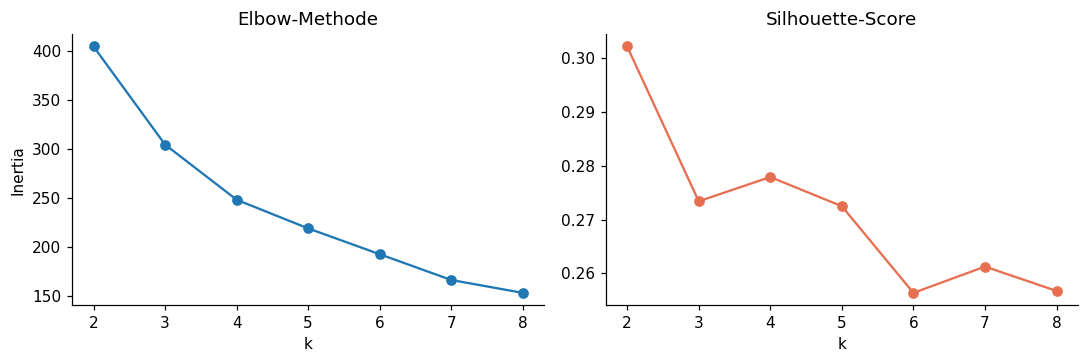

Gewähltes k: 2


In [3]:
CLUSTER_FEATURES = ["anteil_verspaetet", "mittlere_verspaetung", "p90_verspaetung",
                    "stosszeit_effekt", "regen_effekt", "anteil_fernverkehr"]
X = StandardScaler().fit_transform(profil[CLUSTER_FEATURES])

ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=config.RANDOM_STATE).fit(X)
    inertia.append(km.inertia_); silhouette.append(silhouette_score(X, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(list(ks), inertia, marker="o"); axes[0].set_title("Elbow-Methode"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(ks), silhouette, marker="o", color="#e76f51"); axes[1].set_title("Silhouette-Score"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "05_kmeans_wahl_k.png", dpi=200); plt.show()

K = list(ks)[int(np.argmax(silhouette))]   # bei Bedarf manuell anpassen (Elbow beachten)
print("Gewähltes k:", K)
km = KMeans(n_clusters=K, n_init=20, random_state=config.RANDOM_STATE).fit(X)
profil["cluster"] = km.labels_

In [4]:
cluster_profil = profil.groupby("cluster").agg(
    bahnhoefe=("bpuic", "size"), ankuenfte=("ankuenfte", "sum"),
    **{f: (f, "mean") for f in CLUSTER_FEATURES})
display(cluster_profil.round(3))
for c in sorted(profil["cluster"].unique()):
    namen = profil[profil["cluster"] == c].sort_values("ankuenfte", ascending=False)["bahnhof"].head(6).tolist()
    print(f"Cluster {c}: {', '.join(namen)}")
display(pd.crosstab(profil["cluster"], profil["region"]))
cluster_profil.round(3).to_csv(config.OUTPUT_DIR / "05_cluster_profile.csv")

,bahnhoefe,ankuenfte,anteil_verspaetet,mittlere_verspaetung,p90_verspaetung,stosszeit_effekt,regen_effekt,anteil_fernverkehr
cluster,,,,,,,,
0,36,165854.0,0.087,0.970,2.756,0.014,0.040,0.299
1,64,234281.0,0.044,0.558,1.929,0.026,0.006,0.138


Cluster 0: Zürich HB, Zürich Hardbrücke, Olten, Lausanne, Aarau, Renens VD
Cluster 1: Bern, Zürich Oerlikon, Zürich Stadelhofen, Winterthur, St. Gallen, Worblaufen


region,Deutschschweiz,Romandie,Tessin
cluster,,,
0,22,11,3
1,56,6,2


## 2. Geodaten: Karten

In [5]:
import folium

def farbe(wert, vmin, vmax):
    x = min(max((wert - vmin) / (vmax - vmin + 1e-9), 0), 1)
    r, g = int(255 * x), int(180 * (1 - x))
    return f"#{r:02x}{g:02x}40"

vmin, vmax = profil["anteil_verspaetet"].quantile([0.05, 0.95])
karte = folium.Map(location=[46.8, 8.2], zoom_start=8, tiles="OpenStreetMap")
for _, r in profil.iterrows():
    folium.CircleMarker(
        location=[r["lat"], r["lon"]], radius=3 + 12 * np.sqrt(r["ankuenfte"] / profil["ankuenfte"].max()),
        color=farbe(r["anteil_verspaetet"], vmin, vmax), fill=True, fill_opacity=0.85,
        tooltip=f"{r['bahnhof']}: {r['anteil_verspaetet']:.1%} verspätet ({int(r['ankuenfte']):,} Ankünfte)",
    ).add_to(karte)
karte.save(config.OUTPUT_DIR / "05_karte_puenktlichkeit.html")
karte

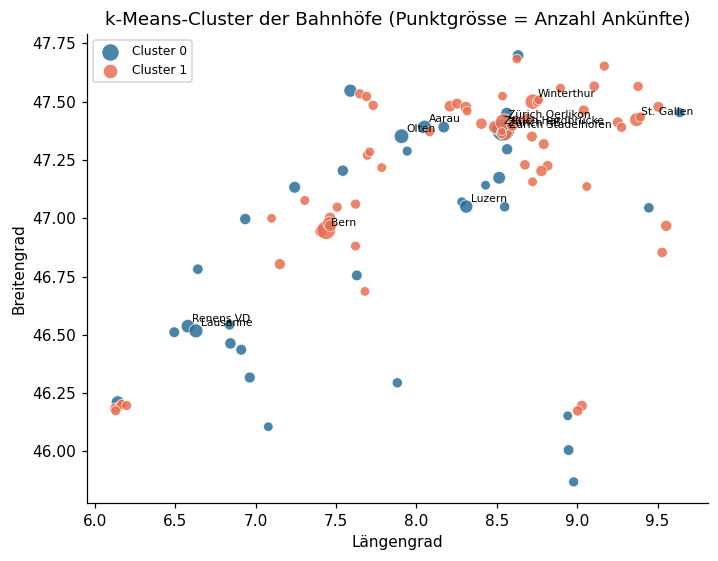

In [6]:
palette = ["#2a6f97", "#e76f51", "#2a9d8f", "#e9c46a", "#6a4c93", "#c1121f", "#8ecae6", "#264653"]
karte2 = folium.Map(location=[46.8, 8.2], zoom_start=8, tiles="OpenStreetMap")
for _, r in profil.iterrows():
    folium.CircleMarker(location=[r["lat"], r["lon"]], radius=6, color=palette[int(r["cluster"]) % 8],
                        fill=True, fill_opacity=0.9, tooltip=f"{r['bahnhof']} – Cluster {int(r['cluster'])}").add_to(karte2)
karte2.save(config.OUTPUT_DIR / "05_karte_cluster.html")

# statische Version für die Folien
fig, ax = plt.subplots(figsize=(8, 5.2))
for c in sorted(profil["cluster"].unique()):
    p = profil[profil["cluster"] == c]
    ax.scatter(p["lon"], p["lat"], s=15 + 200 * p["ankuenfte"] / profil["ankuenfte"].max(),
               color=palette[c % 8], label=f"Cluster {c}", alpha=0.85, edgecolor="white", lw=0.5)
for _, r in profil.nlargest(12, "ankuenfte").iterrows():
    ax.annotate(r["bahnhof"], (r["lon"], r["lat"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Längengrad"); ax.set_ylabel("Breitengrad"); ax.set_aspect(1.45)
ax.set_title("k-Means-Cluster der Bahnhöfe (Punktgrösse = Anzahl Ankünfte)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(config.OUTPUT_DIR / "05_cluster_karte_statisch.png", dpi=200); plt.show()
karte2

## 3. Statistische Tests
Bei sehr grossen Stichproben werden auch kleine Unterschiede signifikant → zusätzlich **Effektstärken** (Cramér's V, η²) berichten.

In [7]:
print("Chi²-Test: Region × verspätet")
tab = pd.crosstab(df["region"], df["verspaetet"])
chi2, p, dof, _ = stats.chi2_contingency(tab)
cramers_v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
display(tab)
print(f"  Chi² = {chi2:,.1f}, df = {dof}, p = {p:.3g}, Cramér's V = {cramers_v:.3f}")

print("\nChi²-Test: Zeitfenster × verspätet")
tab2 = pd.crosstab(df["zeitfenster"], df["verspaetet"])
chi2b, pb, dofb, _ = stats.chi2_contingency(tab2)
print(f"  Chi² = {chi2b:,.1f}, df = {dofb}, p = {pb:.3g}, Cramér's V = {np.sqrt(chi2b / tab2.values.sum()):.3f}")

Chi²-Test: Region × verspätet


verspaetet,0,1
region,,
Deutschschweiz,302914,18547
Romandie,57943,5593
Tessin,14066,1072


  Chi² = 843.0, df = 2, p = 8.79e-184, Cramér's V = 0.046

Chi²-Test: Zeitfenster × verspätet
  Chi² = 799.2, df = 1, p = 8.21e-176, Cramér's V = 0.045


In [8]:
print("ANOVA: mittlere Ankunftsverspätung nach Region")
gruppen = [g["an_delay_min"].values for _, g in df.groupby("region") if len(g) > 30]
f, p_anova = stats.f_oneway(*gruppen)
ss_between = sum(len(g) * (g.mean() - df["an_delay_min"].mean()) ** 2 for g in gruppen)
eta2 = ss_between / ((df["an_delay_min"] - df["an_delay_min"].mean()) ** 2).sum()
print(f"  F = {f:,.2f}, p = {p_anova:.3g}, η² = {eta2:.4f}")
h, p_kw = stats.kruskal(*gruppen)
print(f"  Kruskal-Wallis (robust, da Verspätungen schief verteilt): H = {h:,.2f}, p = {p_kw:.3g}")
display(df.groupby("region")["an_delay_min"].agg(["count", "mean", "median", "std"]).round(2))

ANOVA: mittlere Ankunftsverspätung nach Region
  F = 19.90, p = 2.27e-09, η² = 0.0001


  Kruskal-Wallis (robust, da Verspätungen schief verteilt): H = 2,075.56, p = 0


,count,mean,median,std
region,,,,
Deutschschweiz,321461,0.75,0.43,2.47
Romandie,63536,0.77,0.17,3.43
Tessin,15138,0.89,0.28,3.56


In [9]:
print("Korrelation: Niederschlag vs. Anteil verspätet (aggregiert pro Bahnhof und Stunde)")
stunde = (df.assign(stunde_ts=pd.to_datetime(df["ankunft_soll"]).dt.floor("h"))
            .groupby(["bpuic", "stunde_ts"])
            .agg(anteil=("verspaetet", "mean"), niederschlag=("niederschlag", "first"), n=("verspaetet", "size"))
            .query("n >= 3"))
r_p, p_p = stats.pearsonr(stunde["niederschlag"], stunde["anteil"])
r_s, p_s = stats.spearmanr(stunde["niederschlag"], stunde["anteil"])
print(f"  n = {len(stunde):,} Bahnhof-Stunden")
print(f"  Pearson r = {r_p:.3f} (p = {p_p:.3g}) | Spearman ρ = {r_s:.3f} (p = {p_s:.3g})")

Korrelation: Niederschlag vs. Anteil verspätet (aggregiert pro Bahnhof und Stunde)


  n = 26,552 Bahnhof-Stunden
  Pearson r = 0.084 (p = 2.02e-42) | Spearman ρ = 0.080 (p = 1.02e-38)


## 4. Interpretation
*(Stand: echte Daten)*
- **Cluster (k = 2, gewählt per Silhouette):** Cluster 0 (36 Bahnhöfe, z. B. Zürich HB, Olten, Lausanne, Aarau) sind die *verspätungsanfälligen Knoten*: 8,7 % verspätet, mehr Fernverkehr (30 %) und grössere Empfindlichkeit für Regen. Cluster 1 (64 Bahnhöfe, z. B. Bern, Oerlikon, Winterthur, St. Gallen) ist *pünktlich* mit 4,4 % und überwiegend S-Bahn. **11 von 17 Romandie-Bahnhöfen** liegen im anfälligen Cluster, aber nur 22 von 78 in der Deutschschweiz.
- **Karte:** Die unpünktlichsten Bahnhöfe liegen fast alle im Kanton Waadt (Yverdon 15,5 %, Palézieux 13,6 %, Lausanne 12,2 %, Renens, Morges, Vevey, Montreux, Aigle) sowie in Basel SBB (12,1 %) und Biel (10,0 %).
- **Tests:** Alle Unterschiede sind wegen der sehr grossen Stichprobe hoch signifikant (p < 0,001), die **Effektstärken sind aber klein**: Chi² Region × verspätet: Cramér's V = 0,046; Zeitfenster × verspätet: V = 0,045; ANOVA mittlere Verspätung nach Region: η² = 0,0001 (der Kruskal-Wallis-Test bestätigt die Unterschiede robust). Korrelation Niederschlag ↔ Anteil verspätet pro Bahnhof-Stunde: r = 0,08 (schwach positiv). → Statistisch gesichert, aber praktisch erklären Region, Tageszeit und Regen jeweils nur einen kleinen Teil der Verspätungen.
